# VADER validation on 40 hand-labelled tweets

Original file name: `VADER Model Evaluation.ipynb`

**Runs from the data committed in this repository** (`data/derived/`, `data/prices/`, `data/tweet_counts/`, `data/annotation/`). Environment: see `requirements.txt` (Python 3.11, pandas 1.5.3). Cells 3-5 re-draw the 40-tweet sample (`random_state=42`) and write a blank annotation template (git-ignored); cells 7 onwards read the committed `data/annotation/sample_tweets_annotated.csv`, which holds the hand labels.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, accuracy_score

In [2]:
df = pd.read_csv('../data/derived/twitter_sentiment_scores_2021.csv')

# Making a random sample 40 tweets and adding human sentiment column for manual annotation

In [3]:
sample_df = df.sample(n=40, random_state=42)

In [4]:
sample_df['Human_Sentiment'] = ''

In [5]:
sample_df.to_csv('../data/annotation/sample_tweets_annotation_template.csv', index=False)

# sklearn.metrics evaluation

In [6]:
# Assuming the file path is 'sample_tweets_for_annotation.csv'
annotated_df = pd.read_csv('../data/annotation/sample_tweets_annotated.csv')

In [7]:
predicted = annotated_df['Sentiment']
true = annotated_df['Human_Sentiment']

In [9]:
labels = ['POSITIVE', 'NEGATIVE', 'NEUTRAL']

# Calculate precision and recall for each class
precision = precision_score(true, predicted, labels=labels, average=None)
recall = recall_score(true, predicted, labels=labels, average=None)
accuracy = accuracy_score(true, predicted)

# Combine the metrics into a DataFrame for better presentation
evaluation_df = pd.DataFrame({
    'Sentiment': labels,
    'Precision': precision,
    'Recall': recall
})

# Add overall accuracy to the DataFrame
evaluation_df = evaluation_df.append({
    'Sentiment': 'OVERALL',
    'Precision': accuracy,
    'Recall': accuracy
}, ignore_index=True)

evaluation_df

<ipykernel> FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  evaluation_df = evaluation_df.append({


,Sentiment,Precision,Recall
0,POSITIVE,0.962963,0.896552
1,NEGATIVE,0.333333,0.666667
2,NEUTRAL,0.857143,0.750000
3,OVERALL,0.850000,0.850000


In [10]:
# Convert the metrics to percentages
precision_percentage = precision * 100
recall_percentage = recall * 100
accuracy_percentage = accuracy * 100

# Create a new DataFrame with the desired format
evaluation_df_transposed = pd.DataFrame({
    'POSITIVE': [precision_percentage[0], recall_percentage[0], accuracy_percentage],
    'NEGATIVE': [precision_percentage[1], recall_percentage[1], accuracy_percentage],
    'NEUTRAL': [precision_percentage[2], recall_percentage[2], accuracy_percentage]
}, index=['Precision', 'Recall', 'Overall'])

# Display the transposed DataFrame
evaluation_df_transposed

,POSITIVE,NEGATIVE,NEUTRAL
Precision,96.296296,33.333333,85.714286
Recall,89.655172,66.666667,75.000000
Overall,85.000000,85.000000,85.000000


# Bar Plot

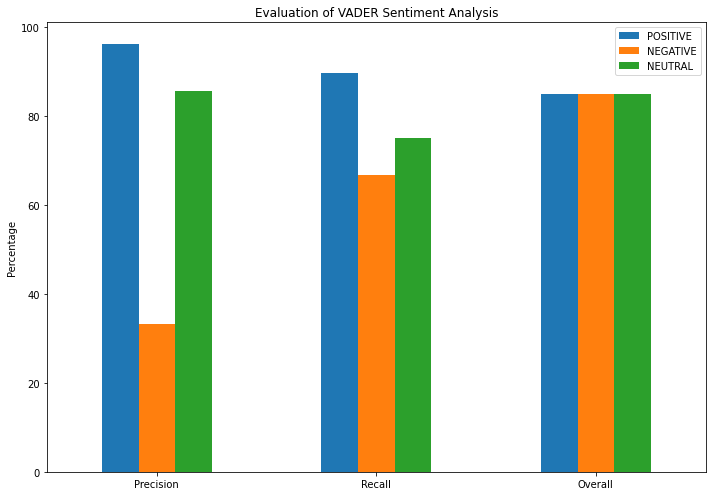

In [13]:
evaluation_df_transposed.plot(kind='bar', figsize=(10,7))
plt.title('Evaluation of VADER Sentiment Analysis')
plt.ylabel('Percentage')
plt.xticks(rotation=0)  # This will ensure the x-axis labels are horizontal
plt.legend(loc='upper right')  # Position the legend on the upper right
plt.tight_layout()
plt.show()